# Join carefully: pixels and populations

**Objective:** Join actual sample centres to tract polygons and avoid interpreting tract population as a per-pixel measurement.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A spatial join is a geometric operation, not a causal model. We locate each satellite sample centre within Census tract geometry. Population remains the whole-tract POP100 count. We do not divide that count among pixels or infer how many people experienced a surface condition.

The original Census polygons use geographic longitude/latitude. A point-in-ring test handles polygon holes and multipolygons. Points exactly on a boundary have ambiguous assignment at numerical precision; the method should be declared for formal analysis.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=07_eo_population_joins.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
def in_ring(x,y,ring):
    inside = False
    for a,b in zip(ring, ring[1:]+ring[:1]):
        if (a[1]>y) != (b[1]>y) and x < (b[0]-a[0])*(y-a[1])/(b[1]-a[1])+a[0]:
            inside = not inside
    return inside
def contains(f,x,y):
    g=f["geometry"]
    polys=[g["coordinates"]] if g["type"]=="Polygon" else g["coordinates"]
    return any(in_ring(x,y,p[0]) and not any(in_ring(x,y,h) for h in p[1:]) for p in polys)
groups = {}
# Use every tenth actual sample to keep this pure-Python browser exercise small.
for r in data[::10]:
    for f in tracts:
        if contains(f,r["lon"],r["lat"]):
            groups.setdefault(f["properties"]["GEOID"], []).append(r)
            break
joined = [(g,len(rs),avg("temperature_c",rs)) for g,rs in groups.items() if avg("temperature_c",rs) is not None]
# Independent GEOS point-in-polygon audit of this frozen real snapshot:
assert len(joined) == 155 and sum(s[1] for s in joined) == 689
expected_memberships = {
    "r5c35": "06039001100", "r145c455": "06019005507",
    "r415c375": "06019005100", "r815c555": "06019001500",
}
for sample_id, expected_geoid in expected_memberships.items():
    row = next(r for r in data if r["id"] == sample_id)
    hits = [f["properties"]["GEOID"] for f in tracts if contains(f,row["lon"],row["lat"])]
    assert hits == [expected_geoid], (sample_id, hits)
print("Tracts with joined subsamples:", len(joined), "| joined sample centres:", sum(s[1] for s in joined))

Tracts with joined subsamples: 155 | joined sample centres: 689


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

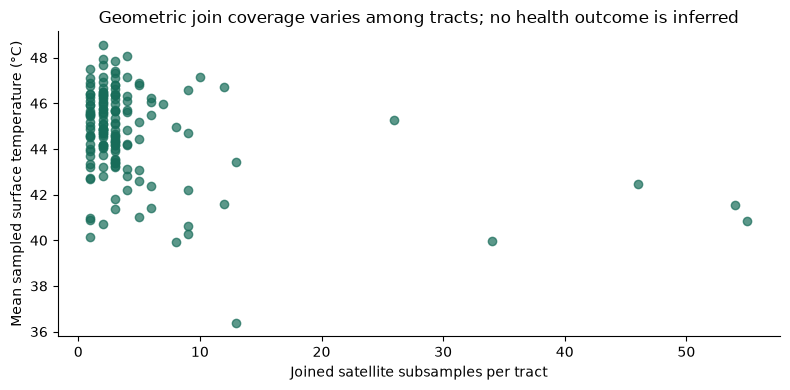

In [3]:
plt.scatter([s[1] for s in joined], [s[2] for s in joined], color="#176c59", alpha=.7)
plt.xlabel("Joined satellite subsamples per tract"); plt.ylabel("Mean sampled surface temperature (°C)")
plt.title("Geometric join coverage varies among tracts; no health outcome is inferred")
plt.tight_layout(); plt.show()

## Interpret and extend

Repeat with every fifth sample. Which tracts gain observations? Why is the tract average not a population-weighted personal exposure? Identify the ecological inference you would avoid.

## Sources and attribution

- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).
- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.